In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, RocCurveDisplay
)

# Load dataset & split identik dengan baseline (random_state=42)
df = pd.read_csv('flood_risk_dataset_india.csv')
X = df.drop(columns=['Flood Occurred'])
y = df['Flood Occurred']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Train: 7000 | Val: 1500 | Test: 1500


In [5]:
num_cols = [
    'Latitude', 'Longitude', 'Rainfall (mm)', 'Temperature (°C)', 'Humidity (%)',
    'River Discharge (m³/s)', 'Water Level (m)', 'Elevation (m)', 'Population Density'
]
bin_cols = ['Infrastructure', 'Historical Floods']
cat_cols = ['Land Cover', 'Soil Type']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# Hyperparameter awal Random Forest
rf_params = {
    'n_estimators': 100,
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

advanced_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(**rf_params))
])

advanced_pipeline.fit(X_train, y_train)
print("Hyperparameter Awal Random Forest:", rf_params)

y_val_pred_rf = advanced_pipeline.predict(X_val)
y_val_prob_rf = advanced_pipeline.predict_proba(X_val)[:, 1]

print("\nClassification Report — Random Forest (Validation Set):")
print(classification_report(y_val, y_val_pred_rf, digits=4))

Hyperparameter Awal Random Forest: {'n_estimators': 100, 'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1}

Classification Report — Random Forest (Validation Set):
              precision    recall  f1-score   support

           0     0.4933    0.4966    0.4950       741
           1     0.5053    0.5020    0.5036       759

    accuracy                         0.4993      1500
   macro avg     0.4993    0.4993    0.4993      1500
weighted avg     0.4994    0.4993    0.4993      1500



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.4867,0.4933,0.5349,0.5133,0.4934
1,Random Forest (Advanced),0.4993,0.5053,0.5020,0.5036,0.5073


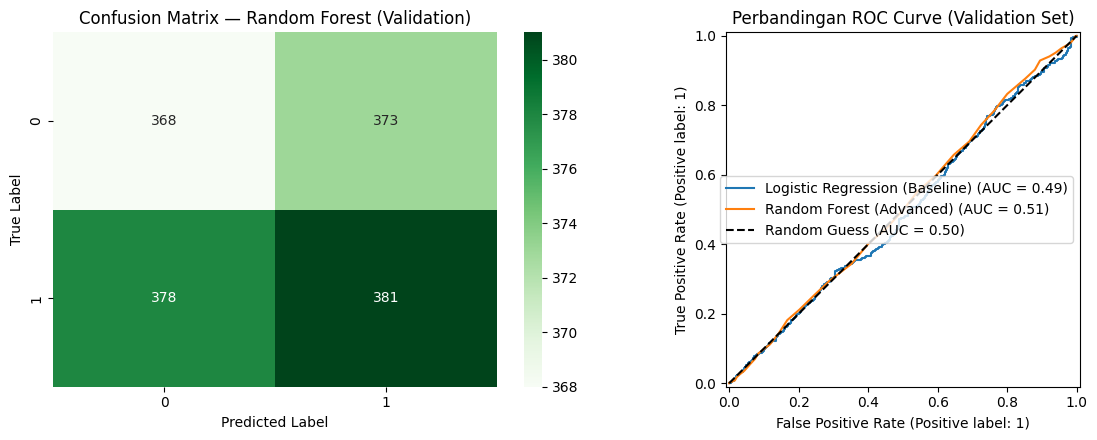

In [6]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        penalty='l2', C=1.0, solver='lbfgs', max_iter=1000, random_state=42
    ))
])
baseline_pipeline.fit(X_train, y_train)

y_val_pred_lr = baseline_pipeline.predict(X_val)
y_val_prob_lr = baseline_pipeline.predict_proba(X_val)[:, 1]

comparison_df = pd.DataFrame([
    {
        'Model': 'Logistic Regression (Baseline)',
        'Accuracy': accuracy_score(y_val, y_val_pred_lr),
        'Precision': precision_score(y_val, y_val_pred_lr),
        'Recall': recall_score(y_val, y_val_pred_lr),
        'F1-Score': f1_score(y_val, y_val_pred_lr),
        'ROC-AUC': roc_auc_score(y_val, y_val_prob_lr)
    },
    {
        'Model': 'Random Forest (Advanced)',
        'Accuracy': accuracy_score(y_val, y_val_pred_rf),
        'Precision': precision_score(y_val, y_val_pred_rf),
        'Recall': recall_score(y_val, y_val_pred_rf),
        'F1-Score': f1_score(y_val, y_val_pred_rf),
        'ROC-AUC': roc_auc_score(y_val, y_val_prob_rf)
    }
])

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm_rf = confusion_matrix(y_val, y_val_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[0])
axes[0].set_title('Confusion Matrix — Random Forest (Validation)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

RocCurveDisplay.from_predictions(y_val, y_val_prob_lr, ax=axes[1], name='Logistic Regression (Baseline)')
RocCurveDisplay.from_predictions(y_val, y_val_prob_rf, ax=axes[1], name='Random Forest (Advanced)')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
axes[1].set_title('Perbandingan ROC Curve (Validation Set)')
axes[1].legend()

plt.tight_layout()
plt.show()